Kernel: `pippe` (pixi env; register with `pixi run kernel`)

# Global runoff ratio

Global-mean annual runoff ratio (R/P) for every member, and each member's anomaly from the default run.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pippe.config as config
import pippe.load as load

In [3]:
GLC_THRESH = 0.5           # mask gridcells with >=GLC_TRESH glaciated area
LAT_BNDS = slice(-90, 90)  # mask Antarctica


def convert_to_mm_day(da):
    """Convert [mm/s, m/s] to mm/day"""
    units = re.split(r'[/\s]+', da.attrs["units"])

    assert units[1] == "s"
    da = da * 86400

    if units[0] == "m":
        da = da * 1000
    
    da.attrs["units"] = "mm/day"
    return da


def annual_mean(da):
    """Calendar-year means of monthly data, weighted by days per month."""
    days = da["time"].dt.days_in_month
    weights = days.groupby("time.year") / days.groupby("time.year").sum()
    return (da * weights).groupby("time.year").sum("time", min_count=1)


def global_mean(da, weights):
    """Area-weighted mean over lat/lon."""
    return da.weighted(weights.fillna(0)).mean(("lat", "lon"))


def anomaly(ens, ref=config.DEFAULT_KEY):
    """Each member minus the reference member (the default run unless given)."""
    return ens - ens.sel(member=ref).reset_coords(drop=True)

In [4]:
grid = load.open_grid()

In [5]:
pct_glc = load.open_ensemble("PCT_LANDUNIT", gcomp="lnd", freq="month_1")

# Store member, param, minmax for later
member = pct_glc["member"]

# Mask glaciated land
glc_mask = (pct_glc.isel(member=0, time=0, ltype=3) / 100) <= GLC_THRESH

Text(0.5, 1.0, 'glaciated land mask')

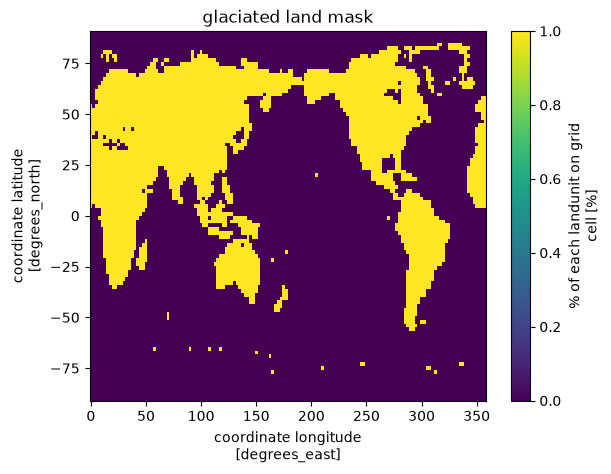

In [6]:
glc_mask.sel(lat=LAT_BNDS).plot()
plt.title("glaciated land mask")

In [7]:
raw = {}

# Load total ET
raw["et"] = load.open_ensemble("EFLX_LH_TOT", gcomp="lnd", freq="month_1").where(glc_mask).sel(lat=LAT_BNDS)

In [8]:
# Compute total precip from convective + large-scale
prc = load.open_ensemble("PRECC", gcomp="atm", freq="month_1").where(glc_mask).sel(lat=LAT_BNDS)
prl = load.open_ensemble("PRECL", gcomp="atm", freq="month_1").where(glc_mask).sel(lat=LAT_BNDS)
pr = prc + prl

raw["pr"] = convert_to_mm_day(pr)

In [9]:
# Load surface runoff (QOVER) and total runoff including subsurface (QRUNOFF)
qover = load.open_ensemble("QOVER", gcomp="lnd", freq="month_1").where(glc_mask).sel(lat=LAT_BNDS)
qrunoff = load.open_ensemble("QRUNOFF", gcomp="lnd", freq="month_1").where(glc_mask).sel(lat=LAT_BNDS)

raw["qover"] = convert_to_mm_day(qover)
raw["qrunoff"] = convert_to_mm_day(qrunoff)

In [10]:
tm = {}
for v, da in raw.items():
    tm[v] = annual_mean(da).mean(dim="year")

In [11]:
tm_zm = {}
for v, da in tm.items():
    tm_zm[v] = da.mean(dim="lon")

tm_zm["qover_ratio"] = tm_zm["qover"] / tm_zm["pr"]
tm_zm["qrunoff_ratio"] = tm_zm["qrunoff"] / tm_zm["pr"]

tm_zm_anom = {}
for v, da in tm_zm.items():
    tm_zm_anom[v] = anomaly(da).compute()
    tm_zm_anom[v] = tm_zm_anom[v].assign_coords(member.coords)

In [12]:
weights = grid["area"] * grid["landfrac"]

tm_gm = {}
for v, da in tm.items():
    tm_gm[v] = global_mean(da, weights)

tm_gm["qover_ratio"] = tm_gm["qover"] / tm_gm["pr"]
tm_gm["qrunoff_ratio"] = tm_gm["qrunoff"] / tm_gm["pr"]

tm_gm_anom = {}
for v, da in tm_gm.items():
    tm_gm_anom[v] = anomaly(da).compute()
    tm_gm_anom[v] = tm_gm_anom[v].assign_coords(member.coords)

## Save to csv

In [13]:
units = "[mm/day]"

# tz_df = None
# tg_df = None
# for tz, tg in zip(tm_zm_anom, tm_gm_anom):
#     if tz_df is None:
#         tz_df = tm_zm_anom[tz].rename(tz+" "+units).to_dataframe()
#     else:
#         _df = tm_zm_anom[tz].rename(tz+" "+units).to_dataframe()
#         tz_df = pd.merge(tz_df, _df)

#     if tg_df is None:
#         tg_df = tm_gm_anom[tg].rename(tg+" "+units).to_dataframe()
#     else:
#         _df = tm_gm_anom[tg].rename(tg+" "+units).to_dataframe()
#         tg_df = pd.merge(tg_df, _df)

In [21]:
tg_df = None
for tg, da in tm_gm_anom.items():
    if tg_df is None:
        tg_df = da.rename(tg+" "+units).to_dataframe()
    else:
        _df = da.rename(tg+" "+units).to_dataframe()
        tg_df = pd.merge(tg_df, _df, on=["param", "minmax"])

In [23]:
tg_df.to_csv("/glade/u/home/bbuchovecky/projects/pi_ppe/data/global_land_mean_anom.csv")

## Parameter range bar plots

In [ ]:
def plot_param_anom_range_bars(da, label, ylim=[None, None], save:str|None=None):
    """Plot bars spanning the min/max for each parameter."""
    ps = [p for sublist in config.PARAM_COLORS.values() for p in sublist]
    colors = {p: color for color, params in config.PARAM_COLORS.items() for p in params}
    xs = np.arange(0, len(ps))

    fig, ax = plt.subplots(layout="constrained", figsize=(9, 7))
    ax.grid(lw=0.5)
    ax.set_axisbelow(True)

    for x, p in zip(xs, ps):
        pair = da.sel(param=p)
        bot = pair.min(dim="member")
        hgt = pair.max(dim="member") - bot
        ax.bar(x, height=hgt, bottom=bot, width=0.5, color=colors[p])

    ax.set_ylim(ylim[0], ylim[1])
    ax.axhline(0, lw=0.8, c="k", ls="--", zorder=0)
    ax.axvline(7.5, lw=0.8, c="k", ls="-", zorder=0)
    ax.set_ylabel(label, fontsize=12)
    ax.set_xticks(xs)
    ax.set_xticklabels(ps, rotation=90, fontsize=10)
    plt.show()

    if save:
        fig.savefig(config.FIG_DIR / save, dpi=300)

In [ ]:
plot_param_anom_range_bars(
    tm_gm_anom["pr"],
    "Land Global Mean Precipitation Change [mm/day]",
    ylim=[-0.09, 0.05],
    save=config.FIG_DIR / "param_anom_range_pr_noglc.png",
)

SyntaxError: closing parenthesis ')' does not match opening parenthesis '[' on line 2 (3785442597.py, line 6)

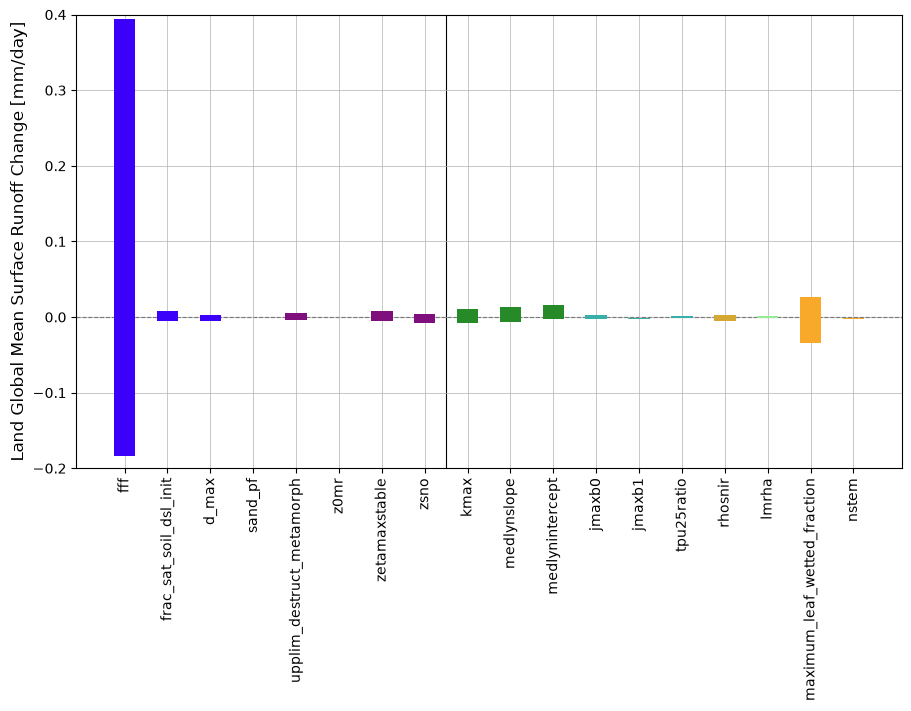

In [ ]:
plot_param_anom_range_bars(
    tm_gm_anom["qover"],
    "Land Global Mean Surface Runoff Change [mm/day]",
    ylim=[-0.2, 0.4],
    save=config.FIG_DIR / "param_anom_range_qover_noglc.png",
)

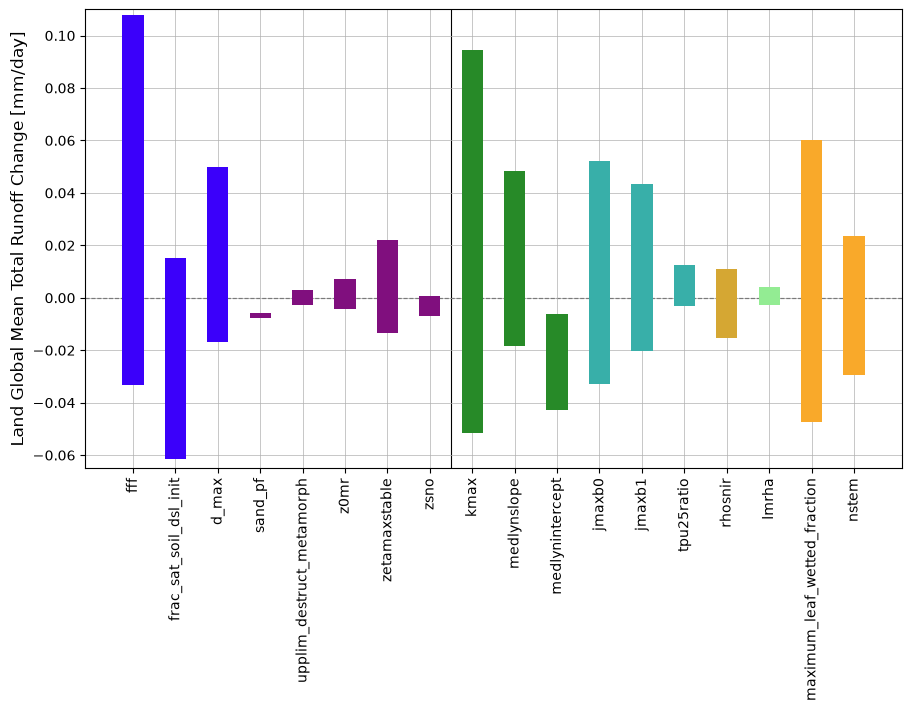

In [ ]:
plot_param_anom_range_bars(
    tm_gm_anom["qrunoff"],
    "Land Global Mean Total Runoff Change [mm/day]",
    ylim=[-0.065, 0.11],
    save=config.FIG_DIR / "param_anom_range_qrunoff_noglc.png",
)

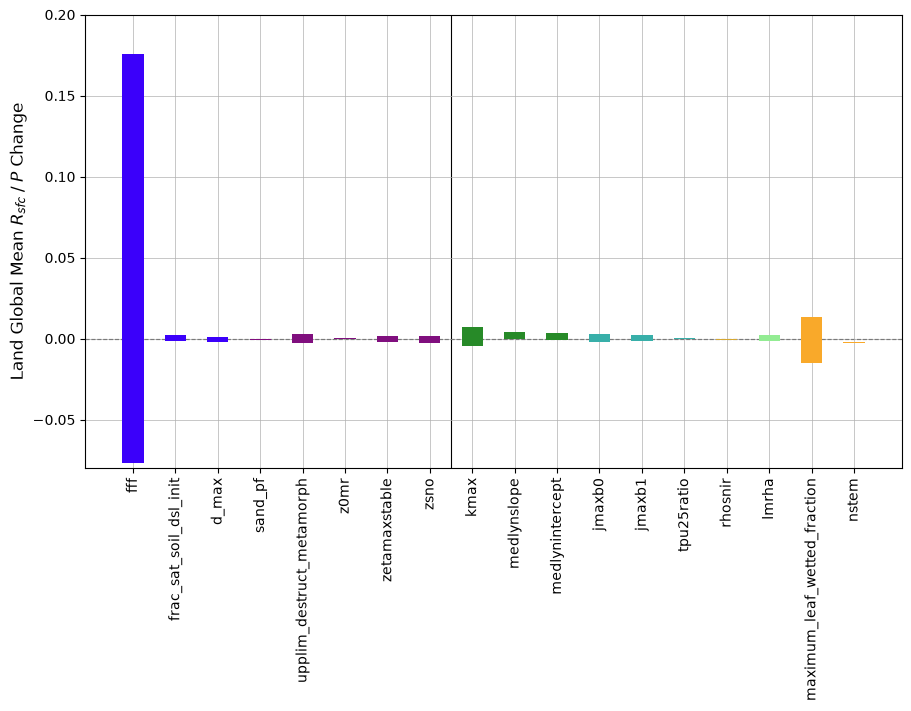

In [ ]:
plot_param_anom_range_bars(
    tm_gm_anom["qover_ratio"],
    "Land Global Mean $R_{sfc} \\; / \\; P$ Change",
    ylim=[-0.08, 0.2],
    save=config.FIG_DIR / "param_anom_range_qover_ratio_noglc.png",
)

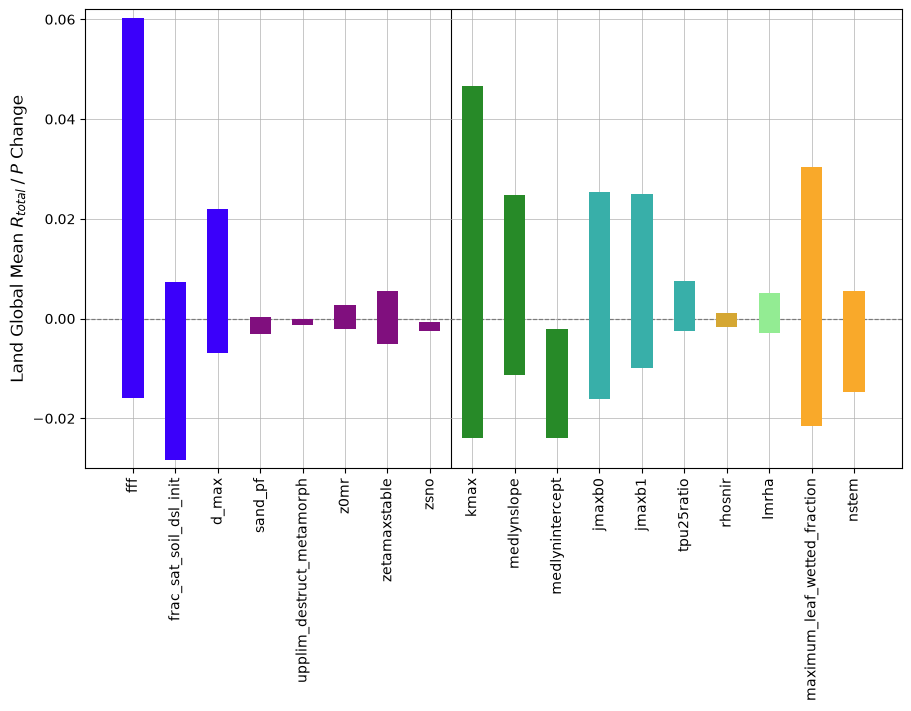

In [ ]:
plot_param_anom_range_bars(
    tm_gm_anom["qrunoff_ratio"],
    "Land Global Mean $R_{total} \\; / \\; P$ Change",
    ylim=[-0.03, 0.062],
    save=config.FIG_DIR / "param_anom_range_qrunoff_ratio_noglc.png",
)

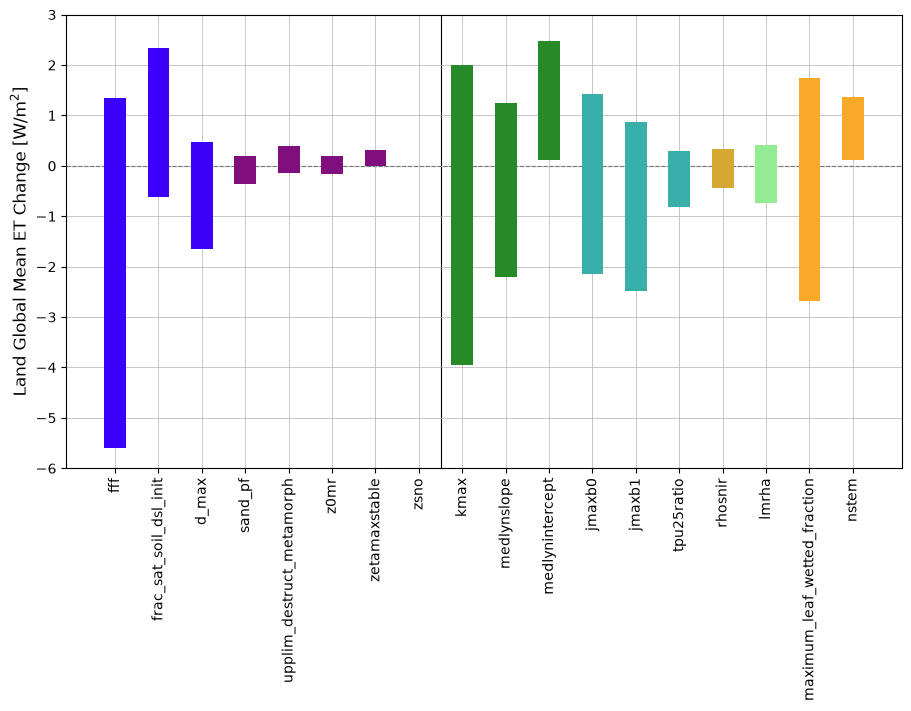

In [ ]:
plot_param_anom_range_bars(
    tm_gm_anom["et"],
    "Land Global Mean ET Change [W/m$^2$]",
    ylim=[-6, 3],
    save=config.FIG_DIR / "param_anom_range_et_noglc.png",
)

## Zonal mean plots

In [ ]:
def zonal_mean_spaghetti_plot(da, label, ylim=[None, None], xlim=[-90, 90], use_colors=False, save:str|None=None):
    """Plot the zonal mean for each member on the same plot."""
    ps = [p for sublist in config.PARAM_COLORS.values() for p in sublist]

    if use_colors:
        colors = {p: color for color, params in config.PARAM_COLORS.items() for p in params}
    else:
        colors = {p: "gray" for p in ps}

    fig, ax = plt.subplots(layout="constrained", figsize=(9, 5))
    ax.grid(lw=0.5)
    ax.set_axisbelow(True)

    for i, p in enumerate(ps):
        for da_mm, ls, line_label in zip(da.sel(param=p), ["--", "-"], ["Minimum perturbation", "Maximum perturbation"]):
            ax.plot(da_mm.lat, da_mm, ls=ls, lw=0.8, color=colors[p], label=line_label if i == 0 else "_nolegend_")

    ax.axhline(0, lw=2, c="k", ls="-", zorder=0)
    ax.legend()
    ax.set_ylim(ylim[0], ylim[1])
    ax.set_xlim(xlim[0], xlim[1])
    ax.set_ylabel(label, fontsize=12)
    ax.set_xlabel("Latitude [\u00b0N]", fontsize=12)
    plt.show()

    if save:
        fig.savefig(config.FIG_DIR / save, dpi=300)

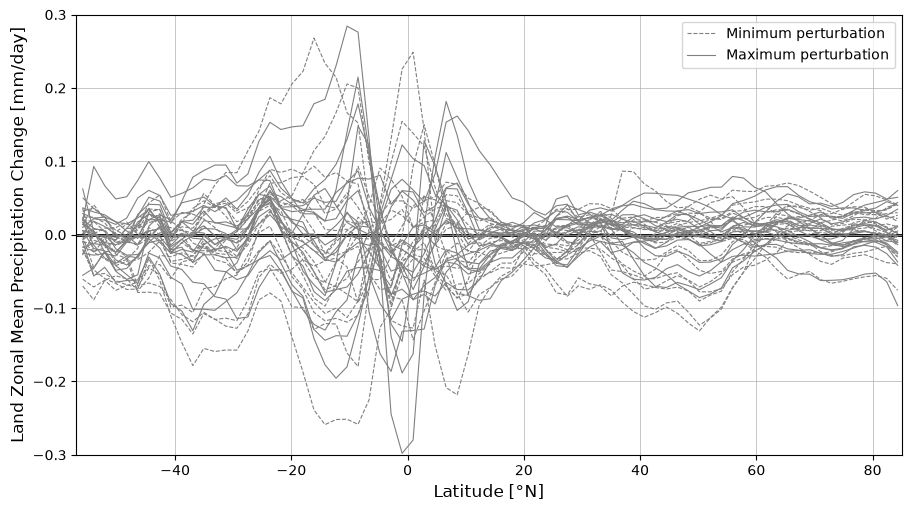

In [ ]:
zonal_mean_spaghetti_plot(
    tm_zm_anom["pr"],
    "Land Zonal Mean Precipitation Change [mm/day]",
    ylim=[-0.3, 0.3],
    xlim=[-57, 85],
    save=config.FIG_DIR / "zonal_mean_lines_pr_noglc.png",
)

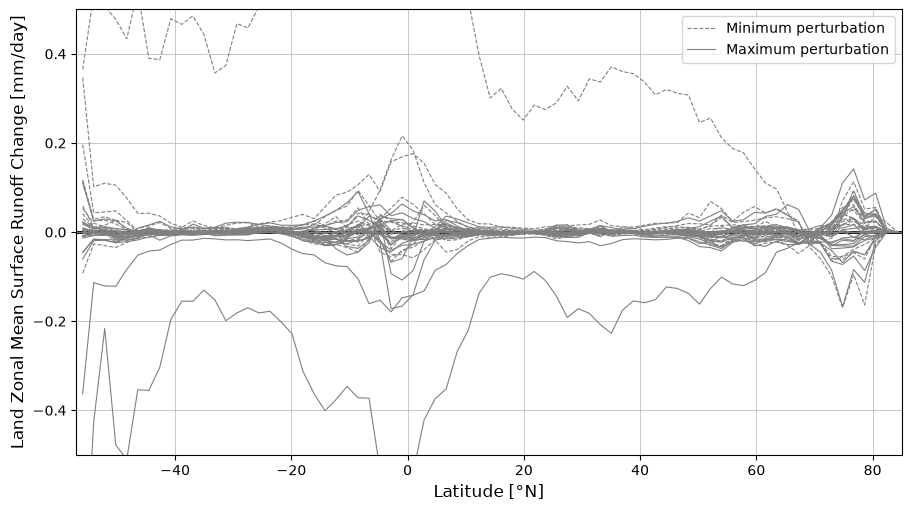

In [ ]:
zonal_mean_spaghetti_plot(
    tm_zm_anom["qover"],
    "Land Zonal Mean Surface Runoff Change [mm/day]",
    ylim=[-0.5, 0.5],
    xlim=[-57, 85],
    save=config.FIG_DIR / "zonal_mean_lines_qover_noglc.png",
)

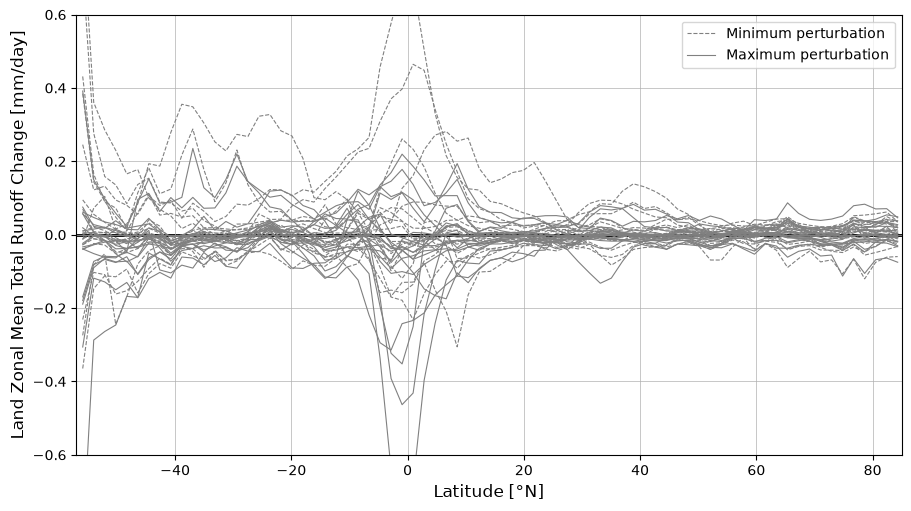

In [ ]:
zonal_mean_spaghetti_plot(
    tm_zm_anom["qrunoff"],
    "Land Zonal Mean Total Runoff Change [mm/day]",
    ylim=[-0.6, 0.6],
    xlim=[-57, 85],
    save=config.FIG_DIR / "zonal_mean_lines_qrunoff_noglc.png",
)

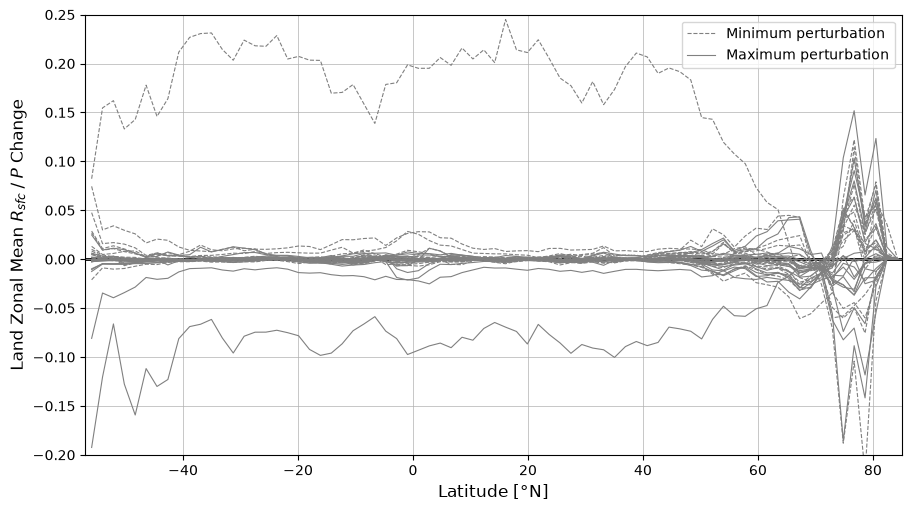

In [ ]:
zonal_mean_spaghetti_plot(
    tm_zm_anom["qover_ratio"],
    "Land Zonal Mean $R_{sfc} \\; / \\; P$ Change",
    ylim=[-0.2, 0.25],
    xlim=[-57, 85],
    save=config.FIG_DIR / "zonal_mean_lines_qover_ratio_noglc.png",
)

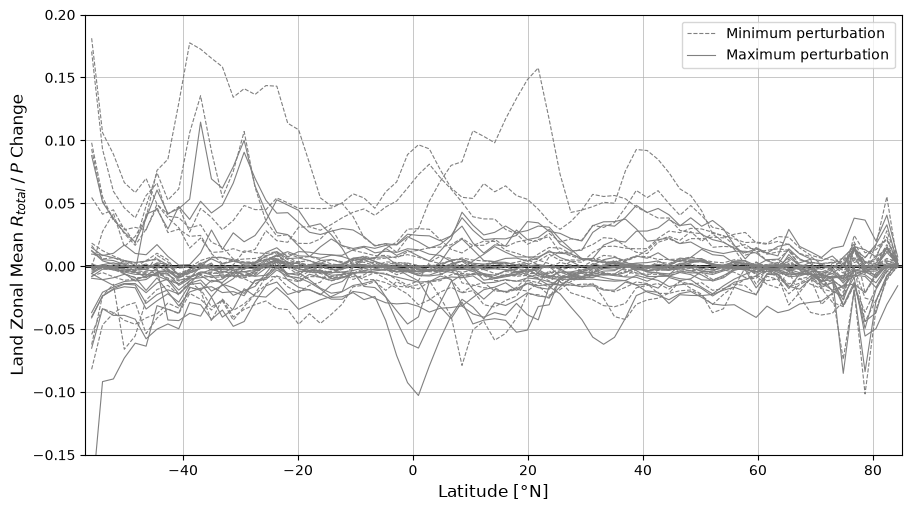

In [ ]:
zonal_mean_spaghetti_plot(
    tm_zm_anom["qrunoff_ratio"],
    "Land Zonal Mean $R_{total} \\; / \\; P$ Change",
    ylim=[-0.15, 0.2],
    xlim=[-57, 85],
    save=config.FIG_DIR / "zonal_mean_lines_qrunoff_ratio_noglc.png",
)

In [ ]:
zonal_mean_spaghetti_plot(
    tm_zm_anom["et"],
    "Land Zonal Mean ET Change [W/m2]",
    ylim=[-16, 12],
    xlim=[-57, 85],
    save=config.FIG_DIR / "zonal_mean_lines_et_noglc.png",
)

NameError: name 'zonal_mean_spaghetti_plot' is not defined